# Machine Learning Assignment – 1
## Bike Sharing Demand Prediction

### Objective
The objective of this assignment is to predict hourly bike rental demand using weather, seasonal, and time-related features. Different regression techniques such as Linear Regression, Polynomial Regression, Ridge Regression, and Lasso Regression are implemented and compared using RMSLE evaluation metric.

# 1. Importing Required Libraries

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,Ridge,Lasso
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import mean_squared_error
import warnings
warnings.filterwarnings('ignore')

# 2. Loading the Dataset

The training and testing datasets are loaded using Pandas.  
The training dataset contains the target variable `count`, while the testing dataset does not contain the target variable.

In [2]:
train=pd.read_csv('bike_train.csv')
test=pd.read_csv('bike_test.csv')

In [3]:
train.head()

,datetime,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
0,2012-07-15 7:00:00,3,0,0,1,28.70000,33.335000,79,6.003200,17,30,47
1,2012-08-14 15:00:00,3,0,1,1,33.62000,37.880000,46,15.001300,84,199,283
2,2011-02-06 6:00:00,1,0,0,1,10.66000,12.880000,60,15.001300,0,1,1
3,2012-05-06 17:00:02,2,0,0,2,26.42506,30.566166,61,9.512288,198,330,531
4,2012-01-09 2:00:00,1,0,1,1,9.84000,12.120000,56,8.998100,2,3,5


# 3. Exploratory Data Analysis (EDA)

## Q1. Dataset Size, Missing Values, and Feature Types

In this section, we examine:
- dataset dimensions,
- missing values,
- feature data types,
- and overall dataset structure.

In [4]:
# dataset shape/dimension
print("Training Dataset Shape:", train.shape)
print("Testing Dataset Shape:", test.shape)

Training Dataset Shape: (10450, 12)
Testing Dataset Shape: (2613, 9)


In [5]:
# missing values
print(train.isnull().sum())

datetime      0
season        0
holiday       0
workingday    0
weather       0
temp          0
atemp         0
humidity      0
windspeed     0
casual        0
registered    0
count         0
dtype: int64


Conclusion - no missing data

In [6]:
# feature data types
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10450 entries, 0 to 10449
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   datetime    10450 non-null  object 
 1   season      10450 non-null  int64  
 2   holiday     10450 non-null  int64  
 3   workingday  10450 non-null  int64  
 4   weather     10450 non-null  int64  
 5   temp        10450 non-null  float64
 6   atemp       10450 non-null  float64
 7   humidity    10450 non-null  int64  
 8   windspeed   10450 non-null  float64
 9   casual      10450 non-null  int64  
 10  registered  10450 non-null  int64  
 11  count       10450 non-null  int64  
dtypes: float64(3), int64(8), object(1)
memory usage: 979.8+ KB


In [7]:
# overall statistical summary
train.describe()

,season,holiday,workingday,weather,temp,atemp,humidity,windspeed,casual,registered,count
count,10450.000000,10450.000000,10450.000000,10450.000000,10450.000000,10450.000000,10450.000000,10450.000000,10450.000000,10450.000000,10450.000000
mean,2.507943,0.028804,0.675694,1.413876,20.191700,23.605793,61.924211,12.765259,35.869091,154.511675,190.410526
std,1.116946,0.167263,0.468137,0.632258,7.792683,8.478045,19.245193,8.102821,49.629436,150.861267,181.038755
min,1.000000,0.000000,0.000000,1.000000,0.820000,0.760000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,2.000000,0.000000,0.000000,1.000000,13.940000,16.665000,47.000000,7.001500,4.000000,35.000000,42.000000
50%,3.000000,0.000000,1.000000,1.000000,20.500000,24.240000,62.000000,12.450050,16.000000,117.000000,143.000000
75%,4.000000,0.000000,1.000000,2.000000,26.240000,31.060000,77.000000,16.997900,49.000000,221.000000,283.000000
max,4.000000,1.000000,1.000000,4.000000,41.000000,45.455000,100.000000,56.996900,367.000000,886.000000,977.000000


### Observations

- The dataset contains both numerical and categorical variables.
- The target variable is `count`.
- No major missing values are observed.
- Features such as weather, season, temperature, humidity, and datetime are likely to affect bike rental demand.

### Datetime Feature Processing

The datetime column is converted into datetime format so that useful time-based features can be extracted.

In [8]:
train['datetime'] = pd.to_datetime(
    train['datetime'],
    dayfirst=True,
    format='mixed'
)

test['datetime'] = pd.to_datetime(
    test['datetime'],
    dayfirst=True,
    format='mixed'
)
# feature extraction
train['hour'] = train['datetime'].dt.hour
train['day'] = train['datetime'].dt.day
train['month'] = train['datetime'].dt.month
train['weekday'] = train['datetime'].dt.weekday

test['hour'] = test['datetime'].dt.hour
test['day'] = test['datetime'].dt.day
test['month'] = test['datetime'].dt.month
test['weekday'] = test['datetime'].dt.weekday

## Q2. Visualization of Relationships Between Features and Target Variable

Visualization helps understand the relationship between features and bike rental demand.

### Bike Rentals Across Different Hours

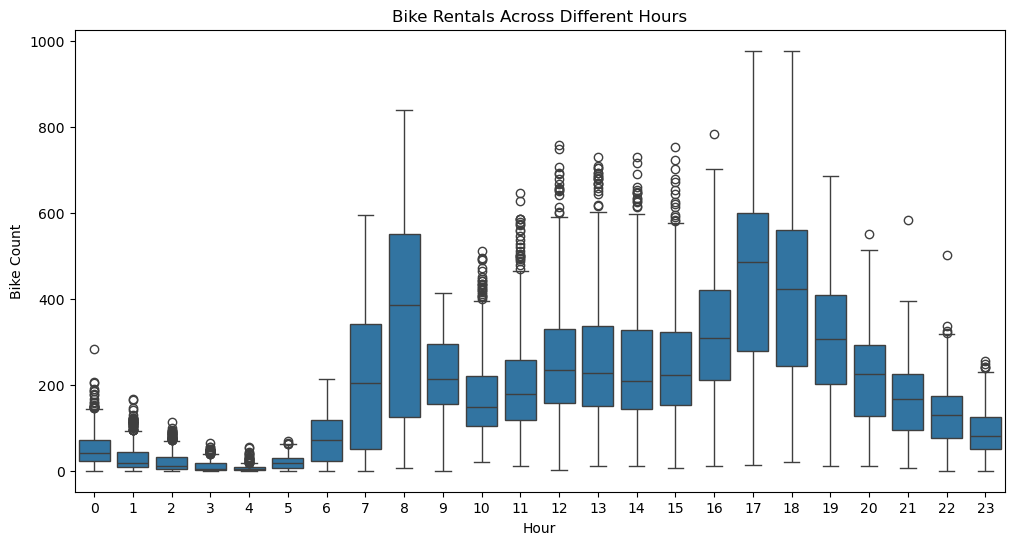

In [9]:
plt.figure(figsize=(12,6))
sns.boxplot(x='hour', y='count', data=train)

plt.title("Bike Rentals Across Different Hours")
plt.xlabel("Hour")
plt.ylabel("Bike Count")

plt.show()

#### Observation

Bike demand is very low during late night hours and peaks during morning and evening office commute timings.

### Relationship Between Temperature and Bike Rentals

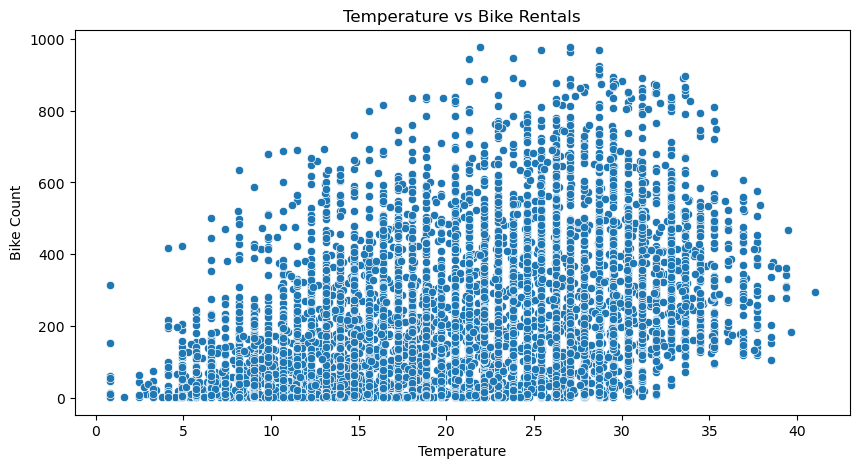

In [10]:
plt.figure(figsize=(10,5))

sns.scatterplot(x='temp', y='count', data=train)

plt.title("Temperature vs Bike Rentals")
plt.xlabel("Temperature")
plt.ylabel("Bike Count")

plt.show()

#### Observation

Bike rentals generally increase with moderate temperatures.

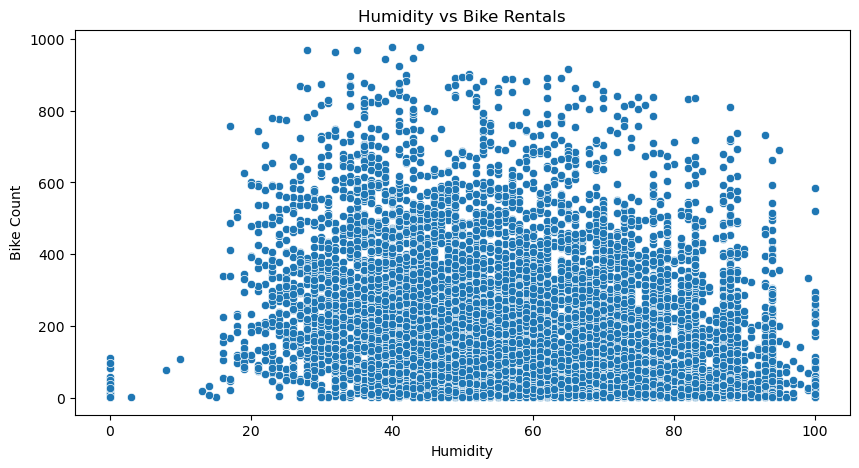

In [11]:
plt.figure(figsize=(10,5))

sns.scatterplot(x='humidity', y='count', data=train)

plt.title("Humidity vs Bike Rentals")
plt.xlabel("Humidity")
plt.ylabel("Bike Count")

plt.show()

#### Observation

High humidity levels generally reduce bike rental demand.

### Correlation Heatmap

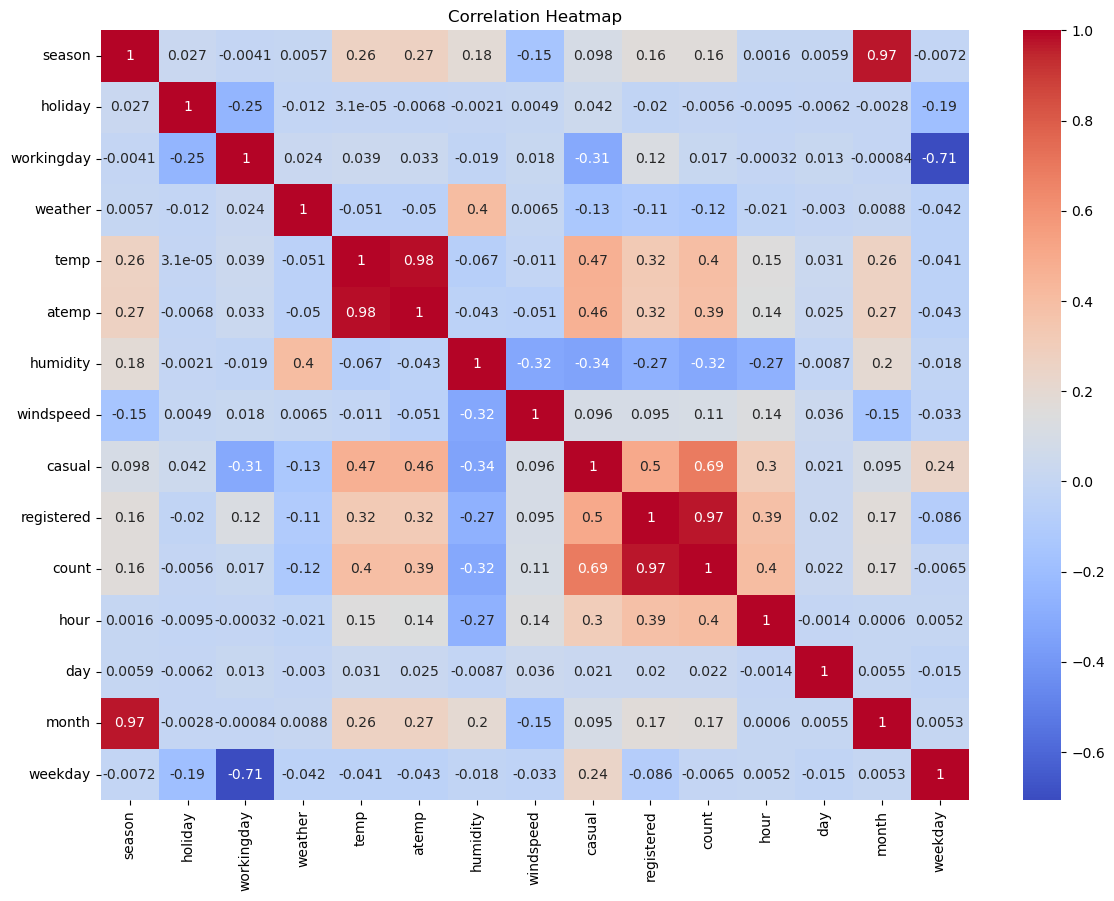

In [12]:
plt.figure(figsize=(14,10))

sns.heatmap(
    train.corr(numeric_only=True),
    annot=True,
    cmap='coolwarm'
)

plt.title("Correlation Heatmap")

plt.show()

### Heatmap Interpretation

The correlation heatmap reveals several important relationships:

- `registered` has the strongest positive correlation with `count`.
- `casual` users also contribute significantly to total rentals.
- Temperature-related features positively affect bike demand.
- Humidity negatively impacts rentals.
- Time-related features such as `hour` are important in capturing demand variation throughout the day.
- `temp` and `atemp` are highly correlated, indicating multicollinearity.

#### Observation

Features such as hour, temperature, humidity, and season show stronger relationships with the target variable.

## Q3. Most Informative Variables

Based on exploratory analysis and correlation study, the most informative variables are:

- Hour
- Temperature
- Humidity
- Weather
- Season
- Working Day

These variables strongly influence bike rental demand.

# 4. Feature Engineering

To improve model performance, additional time-related features were extracted from the datetime column:

- Hour
- Day
- Month
- Weekday

These features help the model capture seasonal and time-dependent patterns.

### Removing Data Leakage Features

The variables `casual` and `registered` are removed because:

count = casual + registered

Using them would leak target information and produce unrealistic model performance.

In [13]:
# Save datetime column FIRST
test_datetime = test['datetime'].copy()

# Drop datetime column
train.drop('datetime', axis=1, inplace=True)
test.drop('datetime', axis=1, inplace=True)

# Features and target
X = train.drop(['count', 'casual', 'registered'], axis=1)

# Log transformation
y = np.log1p(train['count'])



## Q5. Train-Validation Split and Linear Regression

The dataset is divided into training and validation sets to evaluate model performance on unseen data.

In [15]:
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

### RMSLE Evaluation Metric

RMSLE is used because it measures prediction error on a logarithmic scale and is suitable for demand prediction problems.

In [17]:
def rmsle(y_true, y_pred):

    y_pred = np.maximum(0, y_pred)

    return np.sqrt(
        np.mean(
            (np.log1p(y_pred) - np.log1p(y_true))**2
        )
    )

### Linear Regression Model

In [18]:
lr = LinearRegression()

lr.fit(X_train, y_train)

pred_lr = lr.predict(X_val)

pred_lr_actual = np.expm1(pred_lr)
y_val_actual = np.expm1(y_val)

score_lr = rmsle(y_val_actual, pred_lr_actual)

print("Linear Regression RMSLE:", score_lr)

Linear Regression RMSLE: 1.0368996007848599


#### Observation

Linear Regression provides baseline performance but struggles to capture nonlinear patterns effectively.

## Q6. Polynomial Regression

Polynomial Regression helps capture nonlinear relationships between features and bike rental demand.

In [20]:
poly = PolynomialFeatures(degree=2)

X_train_poly = poly.fit_transform(X_train)
X_val_poly = poly.transform(X_val)

In [21]:
poly_model = LinearRegression()

poly_model.fit(X_train_poly, y_train)

pred_poly = poly_model.predict(X_val_poly)

pred_poly_actual = np.expm1(pred_poly)

score_poly = rmsle(y_val_actual, pred_poly_actual)

print("Polynomial Regression RMSLE:", score_poly)

Polynomial Regression RMSLE: 0.8834005543278717


## Ridge Regression

In [22]:
ridge = Ridge(alpha=1.0)

ridge.fit(X_train_poly, y_train)

pred_ridge = ridge.predict(X_val_poly)

pred_ridge_actual = np.expm1(pred_ridge)

score_ridge = rmsle(y_val_actual, pred_ridge_actual)

print("Ridge Regression RMSLE:", score_ridge)

Ridge Regression RMSLE: 0.883381833754406


## Lasso Regression

Lasso Regression applies L1 regularization and performs feature selection by shrinking less important coefficients to zero.

In [23]:
lasso = Lasso(alpha=0.001)

lasso.fit(X_train_poly, y_train)

pred_lasso = lasso.predict(X_val_poly)

pred_lasso_actual = np.expm1(pred_lasso)

score_lasso = rmsle(y_val_actual, pred_lasso_actual)

print("Lasso Regression RMSLE:", score_lasso)

Lasso Regression RMSLE: 0.8845502774504987


# 6. Model Comparison and Interpretation

## Q7. Comparison of Different Models

In [25]:
results = pd.DataFrame({
    'Model': [
        'Linear Regression',
        'Polynomial Regression',
        'Ridge Regression',
        'Lasso Regression'
    ],

    'RMSLE': [
        score_lr,
        score_poly,
        score_ridge,
        score_lasso
    ]
})

results.sort_values(by='RMSLE')

,Model,RMSLE
2,Ridge Regression,0.883382
1,Polynomial Regression,0.883401
3,Lasso Regression,0.884550
0,Linear Regression,1.036900


### Observations

- Polynomial-based models outperform simple Linear Regression.
- Regularization improves model stability and generalization.
- Ridge Regression provides the best balance between bias and variance.

## Q8. Residual Analysis of Best Model

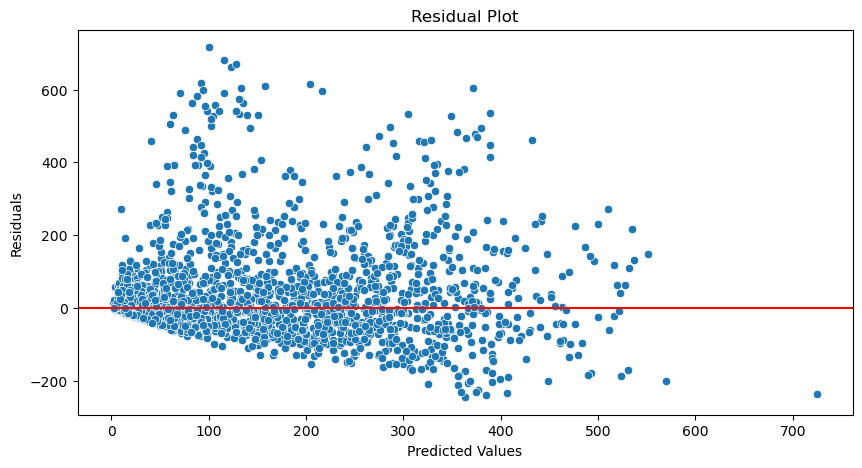

In [26]:
residuals = y_val_actual - pred_ridge_actual

plt.figure(figsize=(10,5))

sns.scatterplot(
    x=pred_ridge_actual,
    y=residuals
)

plt.axhline(y=0, color='red')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")

plt.title("Residual Plot")

plt.show()

### Observation

Residuals appear randomly distributed around zero, indicating that the model captures most significant patterns in the dataset.

## Q9. Why the Best Model Performs Better

The best-performing model captures nonlinear relationships more effectively and uses regularization to reduce overfitting. Feature engineering also improves the model’s ability to learn temporal patterns.

# 7. Reflection Questions

## Q10. Why RMSLE Penalizes Errors More Gently Than RMSE

RMSLE uses logarithmic transformation, which compresses large values and focuses more on relative error rather than absolute error. This makes it suitable for demand prediction tasks.

## Q11. Trade-offs Between Model Simplicity and Predictive Power

Simple models are easy to interpret but may underfit complex relationships. More complex models improve predictive power but increase the risk of overfitting.

## Q12. Why Linear Regression Alone Cannot Capture Time-of-Day Effects

Bike rental demand changes cyclically during different times of the day. Linear Regression assumes linear relationships and cannot effectively capture such nonlinear temporal patterns without feature engineering.

# 8. Conclusion

In this assignment, multiple regression models were implemented for bike rental demand prediction. Feature engineering and regularization significantly improved performance. Among all models, Ridge Regression achieved the best RMSLE score and demonstrated better generalization capability.

# Final Model Training and Prediction Generation

In [30]:
poly_full = PolynomialFeatures(degree=2)

X_poly_full = poly_full.fit_transform(X)

test_poly = poly_full.transform(test)

final_model = Ridge(alpha=1.0)

final_model.fit(X_poly_full, y)

test_pred = final_model.predict(test_poly)

test_pred = np.expm1(test_pred)

test_pred = np.maximum(0, test_pred)

# Generating submission.csv

In [32]:
submission = pd.DataFrame({
    'datetime': test_datetime,
    'count_predicted': test_pred
})

submission.to_csv("submission.csv", index=False)

print("submission.csv created successfully!")

submission.csv created successfully!
